# Phishing Email Detection Using NLP
This notebook implements a complete pipeline for detecting phishing emails using NLP. 
It includes data cleaning, EDA, feature extraction, model training with cross-validation, hyperparameter tuning, and visualization of results.


## 1. Import Libraries
We will import all the necessary libraries for data handling, visualization, text preprocessing, and machine learning.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download necessary NLTK packages
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


## 2. Load Dataset
Load the phishing email dataset (`phishing_validation_emails.csv`) into a pandas DataFrame.


In [2]:
df = pd.read_csv("phishing_validation_emails.csv")
df.head()


,Email Text,Email Type
0,"Dear Jordan, your subscription has been succes...",Safe Email
1,"Dear Casey, thank you for your purchase. Your ...",Safe Email
2,Congratulations! You've won a $3000 gift card....,Phishing Email
3,You have a new secure message from your bank. ...,Phishing Email
4,Your package delivery is pending. Please provi...,Phishing Email


In [3]:
df['Email Type'] = df['Email Type'].str.strip()
df = df.dropna(subset=['Email Text', 'Email Type'])

y = df['Email Type'].map({'Phishing': 1, 'Safe': 0})


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X = tfidf.fit_transform(df['Email Text'])


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## 3. Inspect Dataset
Check the dataset information, column names, and class distribution.


In [6]:
# Check unique values and missing data in Email Type
print(df['Email Type'].value_counts())
print("Missing values in Email Type:", df['Email Type'].isnull().sum())


Email Type
Safe Email        1000
Phishing Email    1000
Name: count, dtype: int64
Missing values in Email Type: 0


In [7]:
# Create email_length column
df['email_length'] = df['Email Text'].apply(len)


## 4. Data Cleaning
We will lowercase the text, remove URLs, numbers, punctuation, stopwords, and apply lemmatization.


In [8]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()  # lowercase
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)  # remove URLs
    text = re.sub(r'\d+', '', text)  # remove numbers
    text = re.sub(r'[^\w\s]', '', text)  # remove punctuation
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

df['clean_text'] = df['Email Text'].apply(clean_text)
df.head()


,Email Text,Email Type,email_length,clean_text
0,"Dear Jordan, your subscription has been succes...",Safe Email,99,dear jordan subscription successfully renewed ...
1,"Dear Casey, thank you for your purchase. Your ...",Safe Email,73,dear casey thank purchase order shipped soon
2,Congratulations! You've won a $3000 gift card....,Phishing Email,78,congratulation youve gift card click claim prize
3,You have a new secure message from your bank. ...,Phishing Email,68,new secure message bank click read
4,Your package delivery is pending. Please provi...,Phishing Email,95,package delivery pending please provide person...


In [9]:
df['email_length'] = df['Email Text'].apply(lambda x: len(str(x)))
df[['Email Text', 'email_length']].head()


,Email Text,email_length
0,"Dear Jordan, your subscription has been succes...",99
1,"Dear Casey, thank you for your purchase. Your ...",73
2,Congratulations! You've won a $3000 gift card....,78
3,You have a new secure message from your bank. ...,68
4,Your package delivery is pending. Please provi...,95


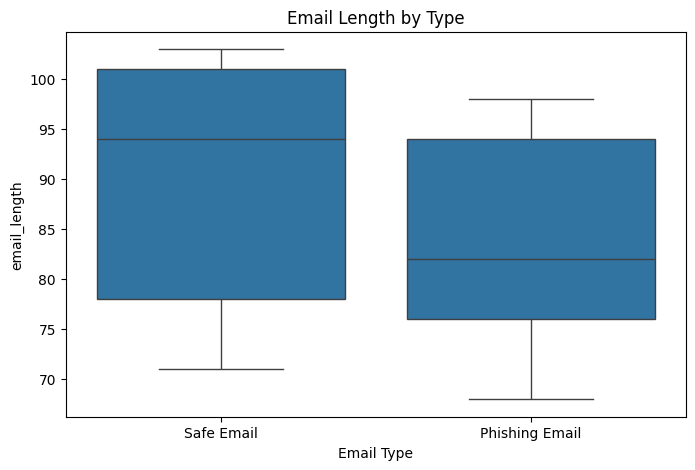

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Email Type', y='email_length', data=df)
plt.title("Email Length by Type")
plt.show()


## 5. Exploratory Data Analysis (EDA)
We will visualize the distribution of email types, email lengths, and compare phishing vs safe emails.


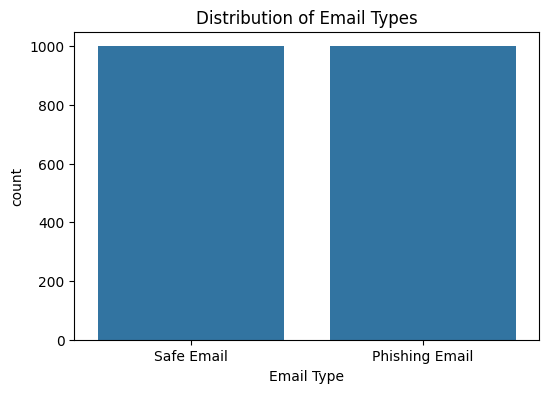

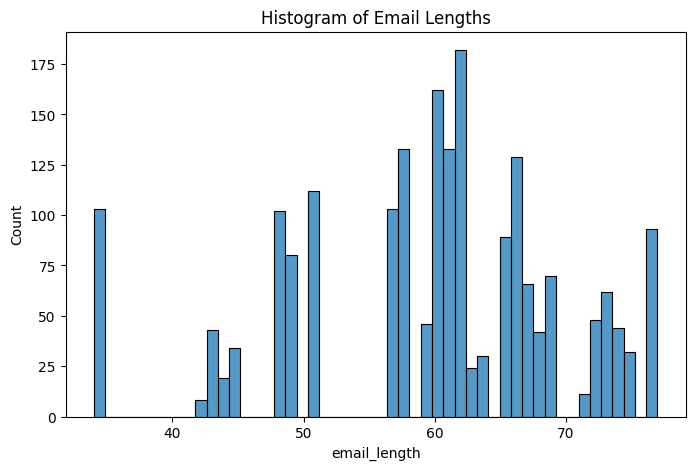

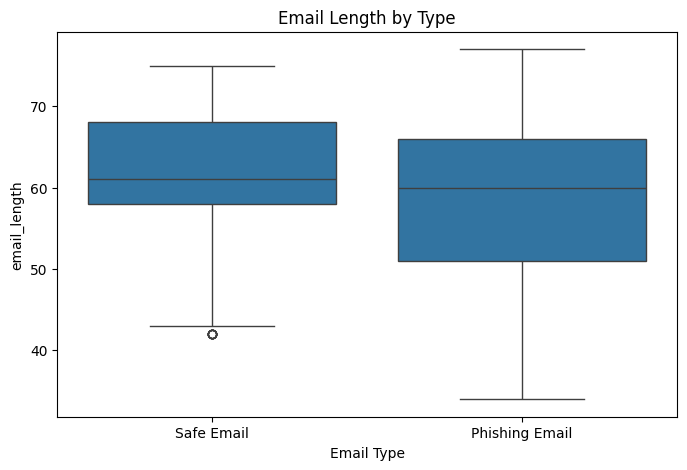

In [11]:
# Bar plot of phishing vs safe emails
plt.figure(figsize=(6,4))
sns.countplot(x='Email Type', data=df)
plt.title("Distribution of Email Types")
plt.show()

# Add email length feature for analysis
df['email_length'] = df['clean_text'].apply(len)

# Histogram of email lengths
plt.figure(figsize=(8,5))
sns.histplot(df['email_length'], bins=50)
plt.title("Histogram of Email Lengths")
plt.show()

# Boxplot of email lengths by type
plt.figure(figsize=(8,5))
sns.boxplot(x='Email Type', y='email_length', data=df)
plt.title("Email Length by Type")
plt.show()


## 6. Encode Labels
Convert 'Email Type' into numerical labels (Phishing = 1, Safe = 0) for model training.


In [12]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['Email Type'])
df['label'].value_counts()


label
1    1000
0    1000
Name: count, dtype: int64

## 7. Train-Test Split
Split the dataset into training and testing sets (80% train, 20% test) with stratification.


In [13]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


## 8. TF-IDF Vectorization
Convert text data into numerical features using TF-IDF vectorization.


In [14]:
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)


## 9. Model Training with Cross-Validation
We will train Logistic Regression, Random Forest, and SVM using 5-fold cross-validation to compare performance.


In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

cv_results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X_train_tfidf, y_train, cv=kf, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name} 5-Fold CV Accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")


Logistic Regression 5-Fold CV Accuracy: 1.0000 ± 0.0000
Random Forest 5-Fold CV Accuracy: 1.0000 ± 0.0000
SVM 5-Fold CV Accuracy: 1.0000 ± 0.0000


## 10. Hyperparameter Tuning
We perform grid search on Random Forest to find the best combination of parameters.


In [16]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_tfidf, y_train)

print("Best parameters:", grid.best_params_)
best_rf = grid.best_estimator_


Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


## 11. Model Evaluation
Evaluate the best Random Forest model on the test set using accuracy, classification report, and confusion matrix.


Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       200
           1       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



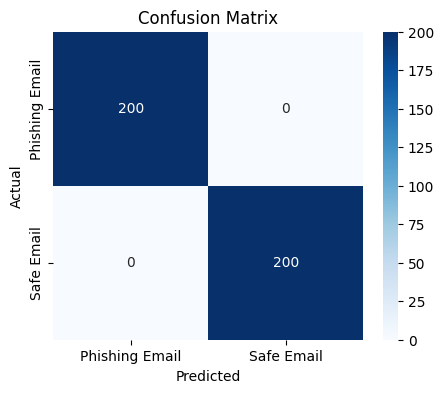

In [17]:
best_rf.fit(X_train_tfidf, y_train)
y_pred = best_rf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## 12. Comparison Plot of Models
Visualize the cross-validation accuracy of all models using a bar plot.


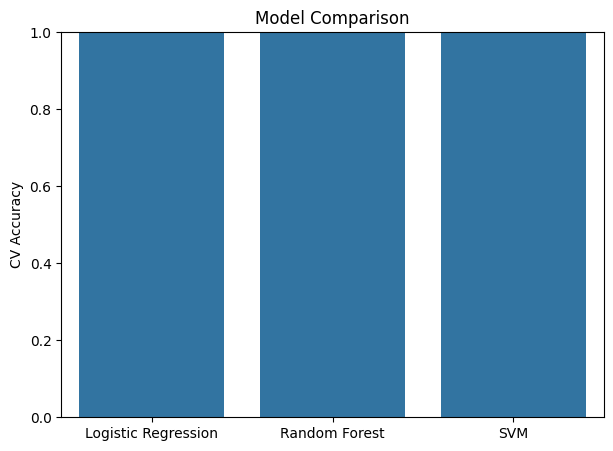

In [18]:
plt.figure(figsize=(7,5))
names = list(cv_results.keys())
scores_mean = [np.mean(cv_results[name]) for name in names]
sns.barplot(x=names, y=scores_mean)
plt.ylabel("CV Accuracy")
plt.title("Model Comparison")
plt.ylim(0,1)
plt.show()


## 13. Save Cleaned Dataset (Optional)
We can save the cleaned and preprocessed dataset for future use.


In [19]:
df.to_csv("cleaned_phishing_emails.csv", index=False)


## 14. ROC Curve & AUC
We will plot the ROC curve and compute the Area Under the Curve (AUC) to evaluate model performance.


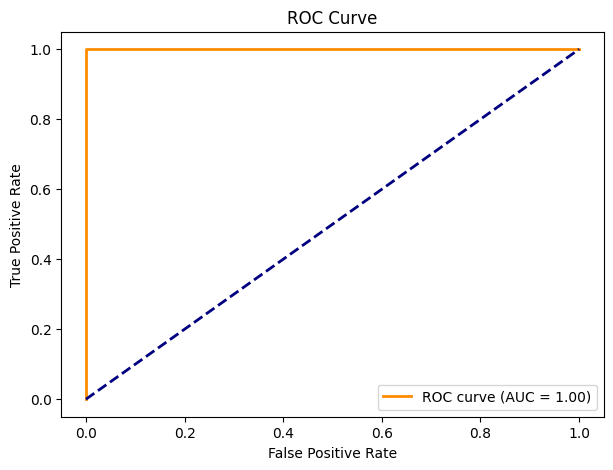

In [20]:
from sklearn.metrics import roc_curve, auc

y_prob = best_rf.predict_proba(X_test_tfidf)[:,1]  # probability for class 1
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()


## 15. Precision-Recall Curve
The precision-recall curve is important for imbalanced datasets, like phishing email detection.


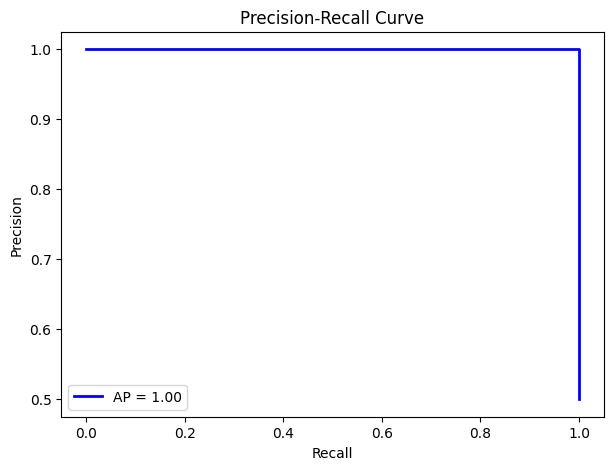

In [21]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7,5))
plt.plot(recall, precision, color='blue', lw=2, label=f'AP = {ap_score:.2f}')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left")
plt.show()


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X = tfidf.fit_transform(df['Email Text'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
best_model = RandomForestClassifier(n_estimators=100, random_state=42)
best_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## 16. Feature Importance
We will display the top 20 most important words (features) from the Random Forest model.


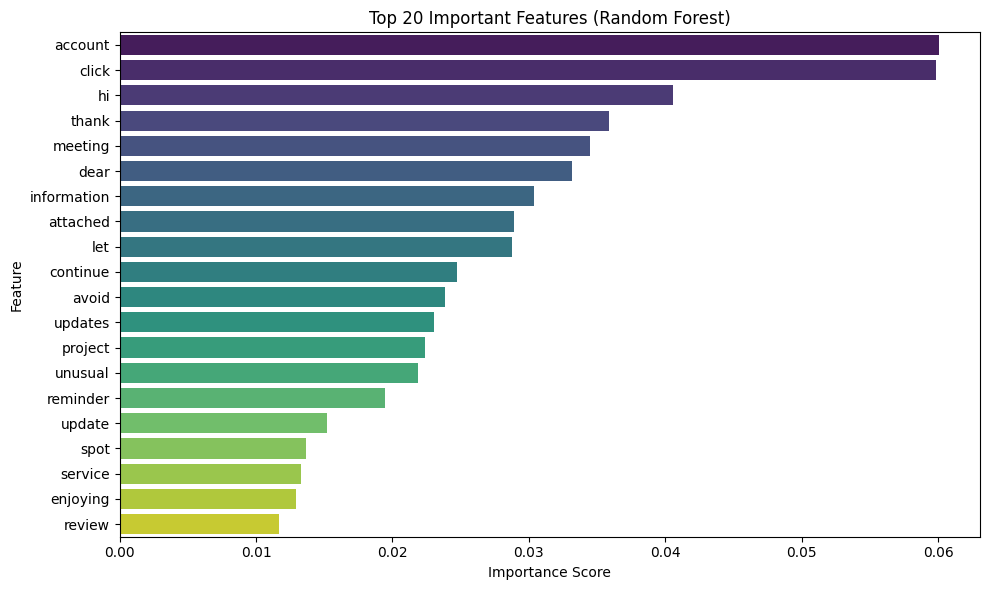

In [23]:
# Feature Importance calculation
importances = best_model.feature_importances_
feature_names = tfidf.get_feature_names_out()
feat_imp = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Get top 20 important features
top_features = feat_imp.sort_values(by='importance', ascending=False).head(20)

# Plot
plt.figure(figsize=(10,6))

sns.barplot(
    x='importance',
    y='feature',
    hue='feature',          # assign hue properly
    data=top_features,
    palette='viridis',
    legend=False            # remove legend
)

plt.title("Top 20 Important Features (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



## 17. Wordcloud of Phishing vs Safe Emails
Visualize the most frequent words in phishing emails vs safe emails using word clouds.


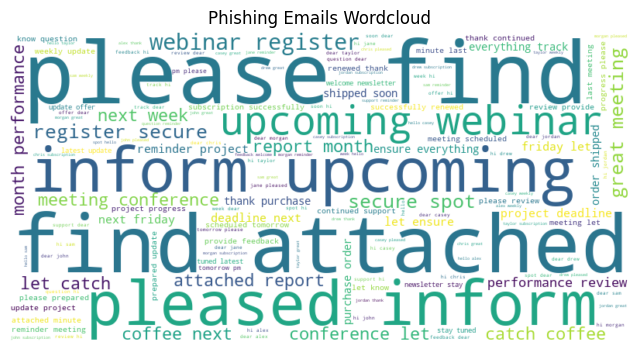

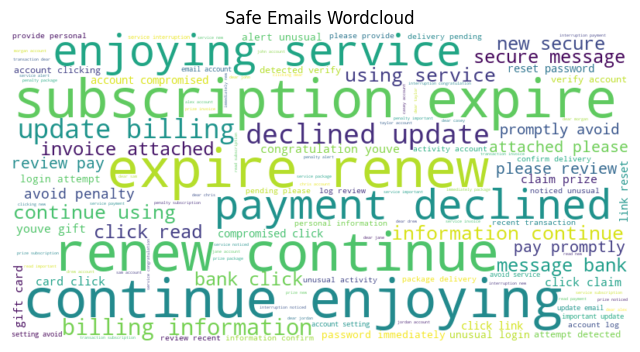

In [24]:
from wordcloud import WordCloud

# Separate phishing and safe emails
phishing_text = " ".join(df[df['label']==1]['clean_text'])
safe_text = " ".join(df[df['label']==0]['clean_text'])

# Phishing WordCloud
plt.figure(figsize=(8,5))
wc_phishing = WordCloud(width=800, height=400, background_color='white').generate(phishing_text)
plt.imshow(wc_phishing, interpolation='bilinear')
plt.axis('off')
plt.title("Phishing Emails Wordcloud")
plt.show()

# Safe WordCloud
plt.figure(figsize=(8,5))
wc_safe = WordCloud(width=800, height=400, background_color='white').generate(safe_text)
plt.imshow(wc_safe, interpolation='bilinear')
plt.axis('off')
plt.title("Safe Emails Wordcloud")
plt.show()


## 18. Cross-Fold Predictions Comparison
Visualize the distribution of accuracies from cross-validation for each model using boxplots.


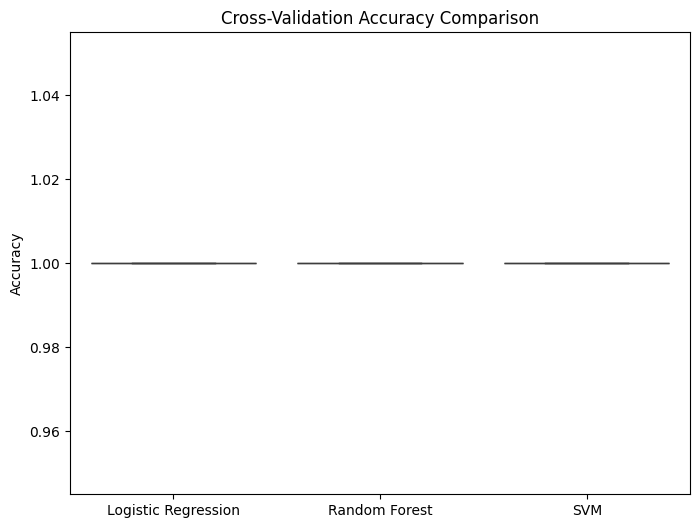

In [25]:
cv_scores_df = pd.DataFrame(cv_results)
plt.figure(figsize=(8,6))
sns.boxplot(data=cv_scores_df)
plt.title("Cross-Validation Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20]
}

rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

In [27]:
grid_results = pd.DataFrame(grid.cv_results_)
grid_results.head()


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.212237,0.007846,0.020947,0.004537,None,50,"{'max_depth': None, 'n_estimators': 50}",1.0,1.0,1.0,1.0,1.0,1.0,0.0,1
1,0.439412,0.005509,0.037386,0.000835,None,100,"{'max_depth': None, 'n_estimators': 100}",1.0,1.0,1.0,1.0,1.0,1.0,0.0,1
2,0.827634,0.010002,0.053239,0.003765,None,200,"{'max_depth': None, 'n_estimators': 200}",1.0,1.0,1.0,1.0,1.0,1.0,0.0,1
3,0.220955,0.005146,0.019763,0.001595,10,50,"{'max_depth': 10, 'n_estimators': 50}",1.0,1.0,1.0,1.0,1.0,1.0,0.0,1
4,0.439079,0.008915,0.035967,0.002326,10,100,"{'max_depth': 10, 'n_estimators': 100}",1.0,1.0,1.0,1.0,1.0,1.0,0.0,1


## 19. Hyperparameter Tuning Results
Compare the accuracy of different hyperparameter combinations for Random Forest using a bar plot.


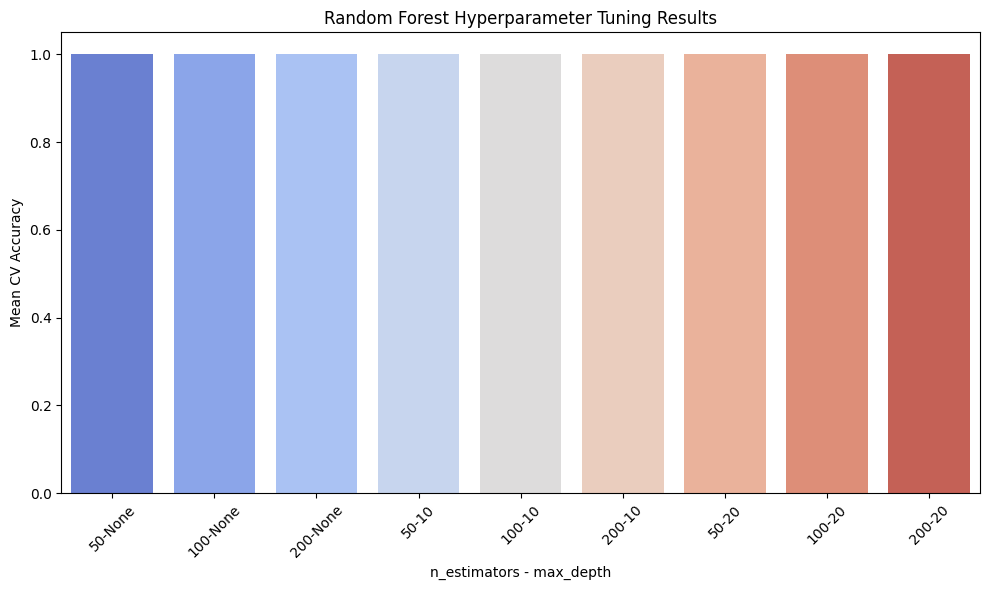

In [28]:
grid_results['param_combo'] = (
    grid_results['param_n_estimators'].astype(str) + "-" +
    grid_results['param_max_depth'].astype(str)
)

plt.figure(figsize=(10,6))
sns.barplot(
    x='param_combo',
    y='mean_test_score',
    hue='param_combo',
    data=grid_results,
    palette='coolwarm',
    legend=False
)

plt.xticks(rotation=45)
plt.ylabel("Mean CV Accuracy")
plt.xlabel("n_estimators - max_depth")
plt.title("Random Forest Hyperparameter Tuning Results")
plt.tight_layout()
plt.show()
